# Derin Öğrenme ve Yapay Sinir Ağları — Canlı Demo

TeknoLab · 28 Kasım 2026

Bu not defterinde bir yapay sinir ağını **hiçbir derin öğrenme kütüphanesi kullanmadan**, yalnızca NumPy ile sıfırdan yazıyoruz. Sunumdaki her kavramın kodda nereye karşılık geldiğini göreceğiz:

1. Tek nöron: "Konsere gideyim mi?"
2. Aktivasyon fonksiyonları
3. Tek nöron XOR'u neden çözemez?
4. İki katmanlı ağ: ileri yayılım, kayıp, geri yayılım, gradyan inişi
5. Öğrenme oranının etkisi
6. El yazısı rakam tanıma

Google Colab'de çalıştırmak için: **Dosya → Not defteri yükle** ile bu dosyayı açın ve hücreleri sırayla çalıştırın. Gerekli kütüphaneler (NumPy, Matplotlib, scikit-learn) Colab'de hazır gelir.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)  # aynı sonuçları almak için sabit tohum
plt.rcParams["figure.figsize"] = (6, 4)

## 1. Tek nöron: "Konsere gideyim mi?"

Nöron, girdileri ağırlıklarla çarpar, toplar, sapmayı ekler ve sonucu bir aktivasyondan geçirir:

$$y = f(w_1 x_1 + w_2 x_2 + w_3 x_3 + b)$$

In [2]:
x = np.array([1, 0, 1])          # hava güzel, arkadaş gelmiyor, bilet ucuz
w = np.array([0.6, 0.3, 0.5])    # her girdinin önemi
b = -0.8                         # sapma: "varsayılan olarak gitmem" eğilimi

z = x @ w + b                    # ağırlıklı toplam
karar = "Git" if z > 0 else "Gitme"
print(f"z = {z:.1f} -> {karar}")

z = 0.3 -> Git


Girdileri değiştirip deneyin: arkadaşınız da gelirse ya da hava kötüyse karar ne olur?

In [3]:
for hava in (0, 1):
    for arkadas in (0, 1):
        for bilet in (0, 1):
            z = np.array([hava, arkadas, bilet]) @ w + b
            print(f"hava={hava} arkadaş={arkadas} bilet={bilet} -> z={z:+.1f} {'Git' if z > 0 else 'Gitme'}")

hava=0 arkadaş=0 bilet=0 -> z=-0.8 Gitme
hava=0 arkadaş=0 bilet=1 -> z=-0.3 Gitme
hava=0 arkadaş=1 bilet=0 -> z=-0.5 Gitme
hava=0 arkadaş=1 bilet=1 -> z=+0.0 Gitme
hava=1 arkadaş=0 bilet=0 -> z=-0.2 Gitme
hava=1 arkadaş=0 bilet=1 -> z=+0.3 Git
hava=1 arkadaş=1 bilet=0 -> z=+0.1 Git
hava=1 arkadaş=1 bilet=1 -> z=+0.6 Git


## 2. Aktivasyon fonksiyonları

Aktivasyon, ağa **eğrilik** katar. Onsuz kaç katman koyarsak koyalım ağ tek bir doğrusal fonksiyon gibi davranır.

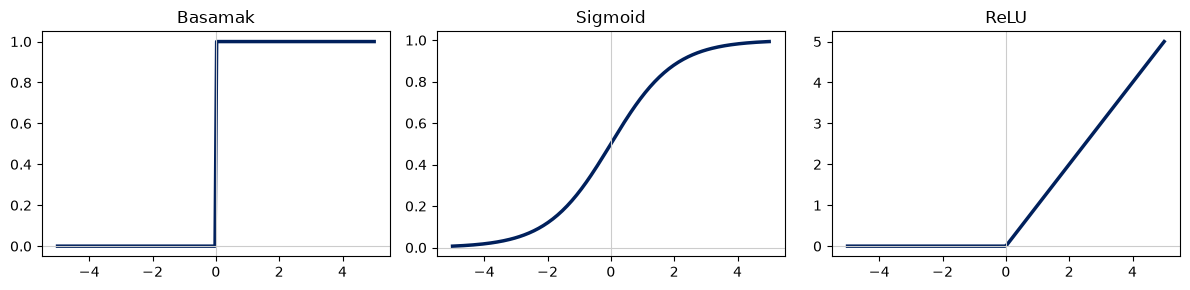

In [4]:
def basamak(z):
    return (z > 0).astype(float)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

z = np.linspace(-5, 5, 200)
fig, eksenler = plt.subplots(1, 3, figsize=(12, 3))
for eksen, (ad, f) in zip(eksenler, [("Basamak", basamak), ("Sigmoid", sigmoid), ("ReLU", relu)]):
    eksen.plot(z, f(z), color="#00205c", linewidth=2.5)
    eksen.set_title(ad)
    eksen.axhline(0, color="#ccc", linewidth=0.8)
    eksen.axvline(0, color="#ccc", linewidth=0.8)
plt.tight_layout()
plt.show()

## 3. Tek nöron XOR'u çözemez

XOR: girdilerden **yalnızca biri** 1 ise çıktı 1'dir. Tek nöron düzlemi tek bir doğruyla böler; aşağıdaki dört noktayı tek doğruyla ayırmak mümkün değildir.

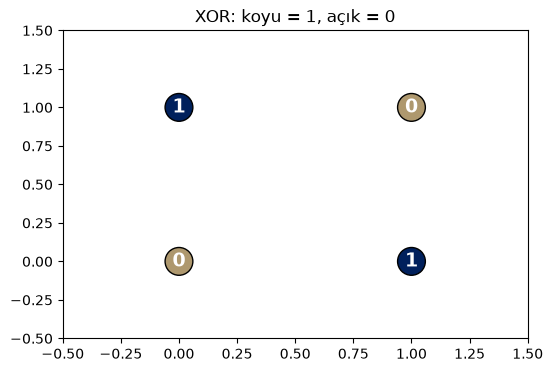

In [5]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

renk = ["#ae986e" if t == 0 else "#00205c" for t in y.ravel()]
plt.scatter(X[:, 0], X[:, 1], c=renk, s=400, edgecolors="black")
for (a, b_), t in zip(X, y.ravel()):
    plt.annotate(str(int(t)), (a, b_), color="white", ha="center", va="center", fontsize=14, weight="bold")
plt.title("XOR: koyu = 1, açık = 0")
plt.xlim(-0.5, 1.5); plt.ylim(-0.5, 1.5)
plt.show()

Önce tek nöronla deneyelim. Eğitim kodunu sonraki bölümde açıklayacağız; burada yalnızca sonucuna bakıyoruz.

In [6]:
def tek_noron_egit(X, y, adim=5000, eta=0.5):
    w = rng.normal(size=(2, 1)); b = np.zeros((1, 1))
    for _ in range(adim):
        p = sigmoid(X @ w + b)
        hata = p - y                      # çapraz entropi + sigmoid'in türevi
        w -= eta * X.T @ hata / len(X)
        b -= eta * hata.mean(keepdims=True)
    return sigmoid(X @ w + b)

print("Tek nöronun tahminleri:", tek_noron_egit(X, y).ravel().round(2))
print("Olması gereken       :", y.ravel())

Tek nöronun tahminleri: [0.5 0.5 0.5 0.5]
Olması gereken       : [0. 1. 1. 0.]


Tahminler 0,5 civarında takılır: tek nöron XOR'u öğrenemez. Çözüm, nöronları **katmanlar** hâlinde birleştirmektir.

## 4. İki katmanlı sinir ağı (sıfırdan)

Öğrenme döngüsünün dört adımı:

1. **İleri yayılım:** girdi ağdan geçer, tahmin üretilir
2. **Kayıp:** tahmin ile gerçek cevap karşılaştırılır (ikili çapraz entropi)
3. **Geri yayılım:** zincir kuralıyla her ağırlığın hatadaki payı (gradyan) hesaplanır
4. **Güncelleme:** $w \leftarrow w - \eta \cdot \partial L / \partial w$

In [7]:
class IkiKatmanliAg:
    """Girdi -> gizli katman (ReLU) -> çıktı (sigmoid / softmax)."""

    def __init__(self, girdi, gizli, cikti):
        # He başlatma: ReLU için uygun ölçek
        self.W1 = rng.normal(0, np.sqrt(2 / girdi), size=(girdi, gizli))
        self.b1 = np.zeros((1, gizli))
        self.W2 = rng.normal(0, np.sqrt(2 / gizli), size=(gizli, cikti))
        self.b2 = np.zeros((1, cikti))

    def ileri(self, X):
        self.X = X
        self.Z1 = X @ self.W1 + self.b1      # 1. katman: ağırlıklı toplam
        self.A1 = relu(self.Z1)              # aktivasyon
        Z2 = self.A1 @ self.W2 + self.b2     # 2. katman
        if Z2.shape[1] == 1:
            self.P = sigmoid(Z2)             # ikili sınıflandırma
        else:
            e = np.exp(Z2 - Z2.max(axis=1, keepdims=True))
            self.P = e / e.sum(axis=1, keepdims=True)   # softmax: çok sınıflı
        return self.P

    def kayip(self, Y):
        P = np.clip(self.P, 1e-9, 1 - 1e-9)
        if Y.shape[1] == 1:
            return float(-np.mean(Y * np.log(P) + (1 - Y) * np.log(1 - P)))
        return float(-np.mean(np.sum(Y * np.log(P), axis=1)))

    def geri(self, Y, eta):
        n = len(Y)
        dZ2 = (self.P - Y) / n               # çıktıdaki hata
        dW2 = self.A1.T @ dZ2
        db2 = dZ2.sum(axis=0, keepdims=True)
        dA1 = dZ2 @ self.W2.T                # hata geriye taşınır
        dZ1 = dA1 * (self.Z1 > 0)            # ReLU'nun türevi: 0 ya da 1
        dW1 = self.X.T @ dZ1
        db1 = dZ1.sum(axis=0, keepdims=True)
        # gradyan inişi: ağırlıkları hatayı azaltan yöne kaydır
        self.W1 -= eta * dW1; self.b1 -= eta * db1
        self.W2 -= eta * dW2; self.b2 -= eta * db2

    def egit(self, X, Y, epoch, eta):
        gecmis = []
        for _ in range(epoch):
            self.ileri(X)
            gecmis.append(self.kayip(Y))
            self.geri(Y, eta)
        return gecmis

Ağın tahminleri: [0.001 1.    0.999 0.   ]
Olması gereken : [0. 1. 1. 0.]


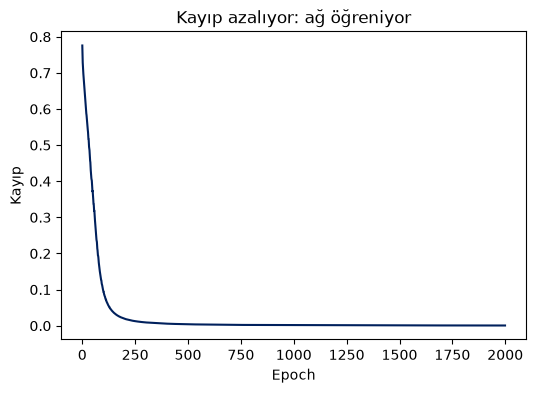

In [8]:
ag = IkiKatmanliAg(girdi=2, gizli=8, cikti=1)
gecmis = ag.egit(X, y, epoch=2000, eta=0.5)

print("Ağın tahminleri:", ag.ileri(X).ravel().round(3))
print("Olması gereken :", y.ravel())

plt.plot(gecmis, color="#00205c")
plt.xlabel("Epoch"); plt.ylabel("Kayıp"); plt.title("Kayıp azalıyor: ağ öğreniyor")
plt.show()

Ağın düzlemi nasıl böldüğüne bakalım. Tek bir doğru yerine **eğri bir sınır** öğrendi:

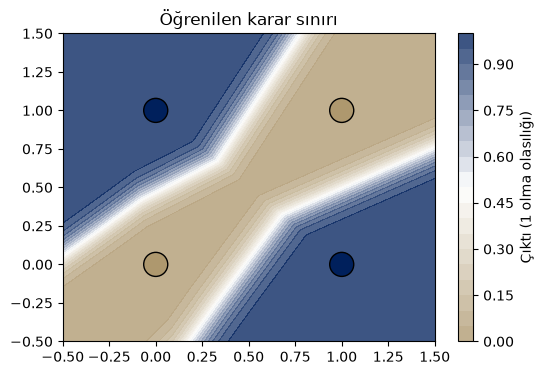

In [9]:
xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
izgara = np.c_[xx.ravel(), yy.ravel()]
zz = ag.ileri(izgara).reshape(xx.shape)

from matplotlib.colors import LinearSegmentedColormap
renk_skalasi = LinearSegmentedColormap.from_list("altin_lacivert", ["#ae986e", "#ffffff", "#00205c"])
plt.contourf(xx, yy, zz, levels=20, cmap=renk_skalasi, alpha=0.8)
plt.colorbar(label="Çıktı (1 olma olasılığı)")
plt.scatter(X[:, 0], X[:, 1], c=renk, s=300, edgecolors="black")
plt.title("Öğrenilen karar sınırı")
plt.show()

## 5. Öğrenme oranının etkisi

Öğrenme oranı (η) adım boyudur. Çok küçükse ağ yavaş öğrenir; çok büyükse vadiyi atlar ve bir yerde takılıp kalabilir.

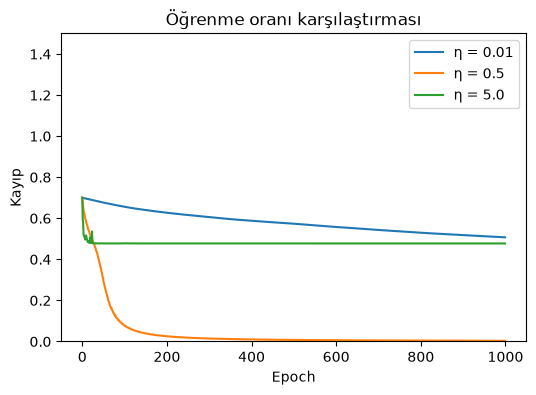

In [10]:
for eta in (0.01, 0.5, 5.0):
    rng = np.random.default_rng(0)
    g = IkiKatmanliAg(2, 8, 1).egit(X, y, epoch=1000, eta=eta)
    plt.plot(g, label=f"η = {eta}")
rng = np.random.default_rng(42)
plt.xlabel("Epoch"); plt.ylabel("Kayıp"); plt.legend(); plt.title("Öğrenme oranı karşılaştırması")
plt.ylim(0, 1.5)
plt.show()

## 6. El yazısı rakam tanıma

Aynı sınıfı, scikit-learn ile gelen **8×8 piksellik 1.797 el yazısı rakam** görüntüsünde kullanalım. Her görüntü 64 sayıdan oluşur; ağ 10 sınıftan birini seçer. Veri **eğitim** ve **test** olarak ikiye ayrılır: test verisini ağ eğitimde hiç görmez.

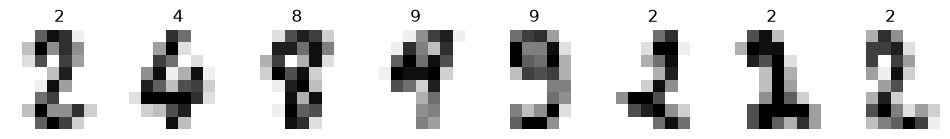

Eğitim: 1400 görüntü | Test: 397 görüntü


In [11]:
from sklearn.datasets import load_digits

rakamlar = load_digits()
X_r = rakamlar.data / 16.0                 # pikselleri 0-1 aralığına ölçekle
Y_r = np.eye(10)[rakamlar.target]          # one-hot: 3 -> [0,0,0,1,0,0,0,0,0,0]

karisik = rng.permutation(len(X_r))
egitim, test = karisik[:1400], karisik[1400:]

fig, eksenler = plt.subplots(1, 8, figsize=(12, 2))
for eksen, i in zip(eksenler, egitim[:8]):
    eksen.imshow(rakamlar.images[i], cmap="gray_r")
    eksen.set_title(rakamlar.target[i]); eksen.axis("off")
plt.show()
print("Eğitim:", len(egitim), "görüntü | Test:", len(test), "görüntü")

Test doğruluğu: %96.2


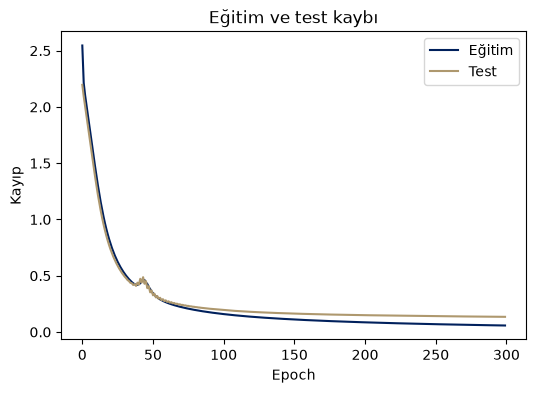

In [12]:
ag_r = IkiKatmanliAg(girdi=64, gizli=32, cikti=10)
egitim_kaybi, test_kaybi = [], []
for epoch in range(300):
    ag_r.ileri(X_r[egitim]); egitim_kaybi.append(ag_r.kayip(Y_r[egitim]))
    ag_r.geri(Y_r[egitim], eta=0.5)
    ag_r.ileri(X_r[test]); test_kaybi.append(ag_r.kayip(Y_r[test]))

dogruluk = (ag_r.ileri(X_r[test]).argmax(axis=1) == rakamlar.target[test]).mean()
print(f"Test doğruluğu: %{dogruluk * 100:.1f}")

plt.plot(egitim_kaybi, label="Eğitim", color="#00205c")
plt.plot(test_kaybi, label="Test", color="#ae986e")
plt.xlabel("Epoch"); plt.ylabel("Kayıp"); plt.legend(); plt.title("Eğitim ve test kaybı")
plt.show()

Ağın hiç görmediği test görüntülerinden bazılarına ve tahminlerine bakalım:

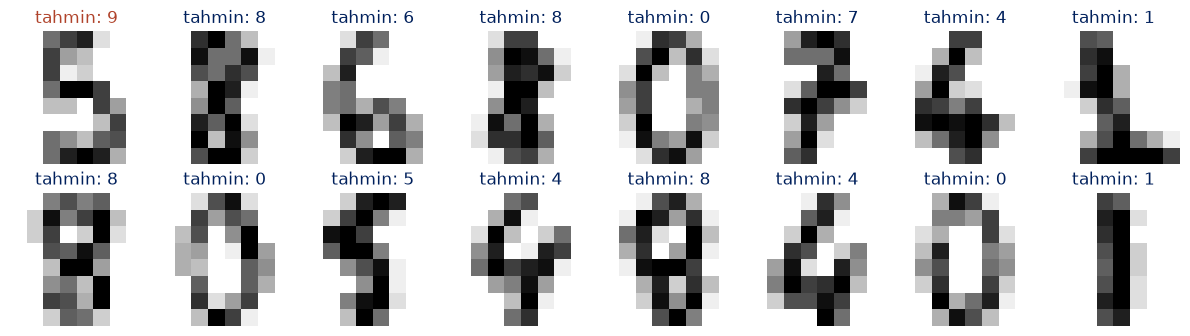

In [13]:
tahmin = ag_r.ileri(X_r[test]).argmax(axis=1)
fig, eksenler = plt.subplots(2, 8, figsize=(12, 3.5))
for eksen, i, t in zip(eksenler.ravel(), test[:16], tahmin[:16]):
    eksen.imshow(rakamlar.images[i], cmap="gray_r")
    dogru = t == rakamlar.target[i]
    eksen.set_title(f"tahmin: {t}", color="#00205c" if dogru else "#b0432b")
    eksen.axis("off")
plt.tight_layout()
plt.show()

## Kendiniz deneyin

- Gizli katmandaki nöron sayısını (`gizli=32`) 4'e düşürün ya da 128'e çıkarın. Doğruluk nasıl değişti?
- Öğrenme oranını (`eta=0.5`) 0,05 ve 3 yapın.
- `relu` yerine `sigmoid` kullanın (geri yayılımdaki türevi de değiştirmeniz gerekir: $\sigma(z)(1-\sigma(z))$).
- Bir sonraki adım: aynı ağı PyTorch ile 12 satırda yazmak (sunumdaki örnek). Geri yayılımı `loss.backward()` sizin yerinize yapar.